In [1]:
%pip install seaborn;

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader

In [3]:
df=pd.read_csv('/Users/remyc/Desktop/python_test/datasets/AIML Dataset.csv')

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
 sns.set(style = "whitegrid")

In [6]:
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [7]:
print(df['isFraud'].value_counts())
df['isFlaggedFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64


isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [8]:
df.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [9]:
float((df['isFraud'].sum() / df['isFraud'].count())*100)

0.12908204481801522

In [10]:
float((df['isFraud'].value_counts()[1]/df.shape[0])*100)

0.12908204481801522

<function matplotlib.pyplot.show(close=None, block=None)>

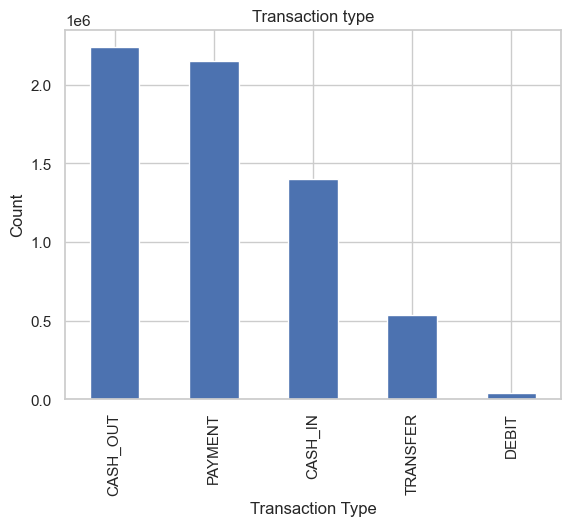

In [11]:
df['type'].value_counts().plot(kind ='bar', title='Transaction type')
plt.xlabel("Transaction Type")
plt.ylabel('Count')
plt.show

In [12]:
#calculating the percentage of fraud (fraud rate) based on the type of transaction
fraud_by_type = df.groupby('type')['isFraud'].mean().sort_values(ascending = False)

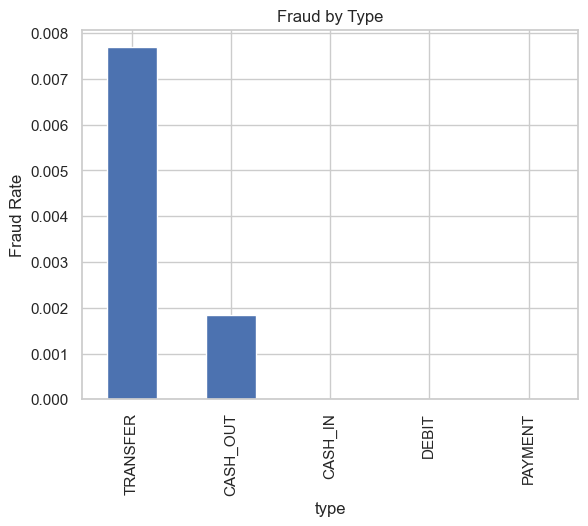

In [13]:
fraud_by_type.plot(kind = 'bar', title = "Fraud by Type")
plt.ylabel("Fraud Rate")
plt.show()

<Axes: xlabel='amount', ylabel='Count'>

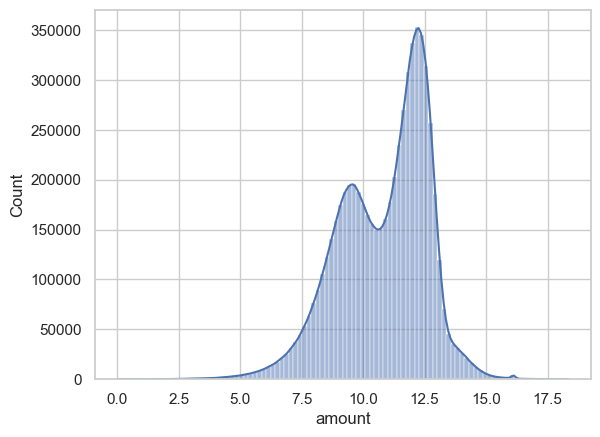

In [14]:
#checking the distribution (hom many entries are a certain amount)
sns.histplot(np.log1p(df['amount']), bins = 100, kde = True)

In [15]:
df['amount'].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

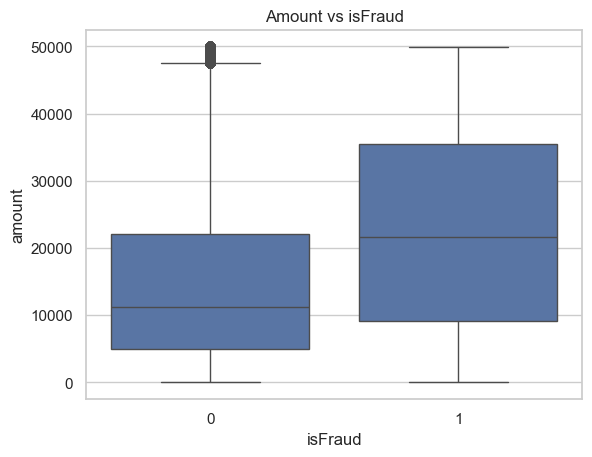

In [16]:
#checking the range of amounts for what is classfied as fraud or not fraud
sns.boxplot(data = df[df['amount']<50000], x = "isFraud", y = "amount")
plt.title("Amount vs isFraud")
plt.show()

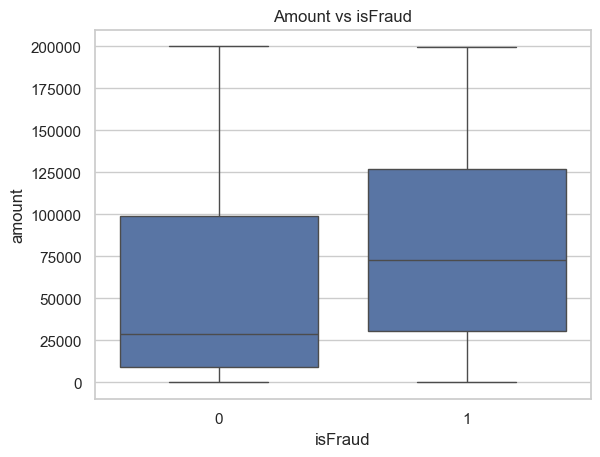

In [17]:
sns.boxplot(data = df[df['amount']<200000], x = "isFraud", y = "amount")
plt.title("Amount vs isFraud")
plt.show()

In [18]:

df['balancediffOrd'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['balancediffDest'] = df['newbalanceDest'] - df['oldbalanceDest']  
if ((df['balancediffOrd']<0).any() and (df['balancediffDest']<0).any()):
    print("negative value")

negative value


In [19]:
#Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
    #   'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
     #  'isFlaggedFraud'

In [20]:
#next i want to find the accounts that have the most amount of transaction in the data.

In [21]:
#getting how many fraudlent transactions happen at a specific step
#and then will graph it. 

fraud_per_step = df[df['isFraud'] == 1]['step'].value_counts().sort_index()
fraud_per_step

step
1      16
2       8
3       4
4      10
5       6
       ..
739    10
740     6
741    22
742    14
743     8
Name: count, Length: 741, dtype: int64

Text(0, 0.5, 'fraud count')

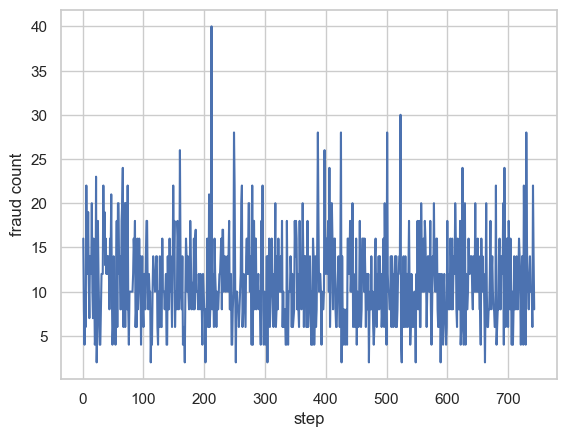

In [22]:
fraud_per_step.plot()
plt.ylabel("fraud count")

In [23]:
#graph makes it seem so that fraud isnt really dependant on time, except for the one 
#spike around step 200

In [24]:
#here we look at what account has sent the most amount of times
df['nameOrig'].value_counts().head(10)

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
Name: count, dtype: int64

In [25]:
#here we look at what accont has received the most aomunt of times
df['nameDest'].value_counts().head(10)

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C1789550256     99
C451111351      99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [26]:
fraud_users = df[df['isFraud']==1]['nameOrig'].value_counts().head(10)
fraud_users2 = df[df['isFraud']==1]['nameDest'].value_counts().head(10)
#plt.plot(df['nameDest'].value_counts().head(10), df['nameOrig'].value_counts().head(10))

In [27]:
fraud_users

nameOrig
C1280323807    1
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C1039979813    1
C2089752665    1
C1614818636    1
C40604503      1
C1970706589    1
Name: count, dtype: int64

In [28]:
fraud_users2

nameDest
C686334805     2
C1193568854    2
C1655359478    2
C1669818195    2
C14138104      2
C1980653895    2
C1837027614    2
C1148781766    2
C1827800010    2
C505532836     2
Name: count, dtype: int64

In [29]:
send_full_balance = df[(df["oldbalanceOrg"] > 0) & (df['newbalanceOrig'] == 0)
    & ((df['type']== 'TRANSFER') | (df['type'] == "CASH_OUT"))]

In [30]:
len(send_full_balance)

1188074

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [32]:
#preparing for modeling
#making a new df without useless columns, and seperating numerical from categorical data
#setting y to the correctly evaluated fraud
#and x to all remainning columns apart from fraud
df2 = df.drop(['nameOrig', 'nameDest', 'isFlaggedFraud'], axis = 1)
categorical = ['type']
numerical = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
y = df2['isFraud']
X = df2.drop('isFraud', axis = 1)

In [33]:
X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size =0.3, stratify = y)

In [34]:
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numerical),
        ('cat', OneHotEncoder(drop='first'), categorical)
    ],
    remainder = 'drop'
)

In [35]:
pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight="balanced", max_iter=1000))
])

In [36]:
pipeline.fit(X_train, y_train)

,steps,"[('prep', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
y_pred = pipeline.predict(X_test)

In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97   1906322
           1       0.02      0.94      0.04      2464

    accuracy                           0.94   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.94      0.97   1908786



In [41]:
#confusion_matrix(y_test, y_pred)

In [40]:
pipeline.score(X_test, y_test)*100

94.46842128976218